In [15]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
FIGURES_DIR = ROOT / "output" / "figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

df_raw = pd.read_csv(ROOT / "data" / "clean" / "gini_2009_2025.csv")
df = df_raw.pivot(index="year", columns="country", values="value").reset_index()

COLOR_PL = "#D55E00"
COLOR_FI = "#009E73"
COLOR_BAD = "#C0392B"
COLOR_BAD_TITLE = "#7B1E14"

plt.style.use("default")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "axes.edgecolor": "#CCCCCC",
    "axes.linewidth": 0.9,
})

df.head()

country,year,Finlandia,Francja,Polska
0,2009,25.9,29.9,31.4
1,2010,25.4,29.8,31.1
2,2011,25.8,30.8,31.1
3,2012,25.9,30.5,30.9
4,2013,25.4,30.1,30.7


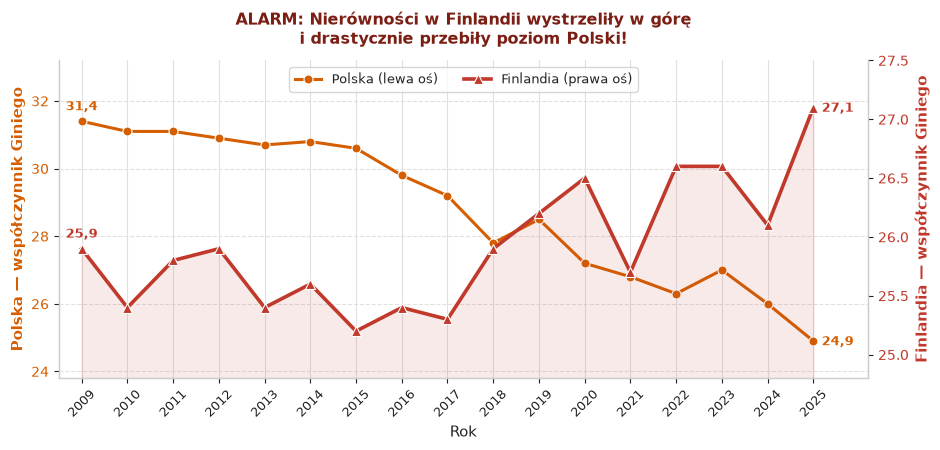

In [16]:
fig, ax1 = plt.subplots(figsize=(9.5, 4.6))

l1 = ax1.plot(
    df["year"], df["Polska"],
    color=COLOR_PL, marker="o", markersize=6.5, linewidth=2.2,
    markeredgecolor="white", markeredgewidth=0.8,
    label="Polska (lewa oś)", zorder=3
)
ax1.set_ylim(23.8, 33.2)
ax1.set_ylabel("Polska — współczynnik Giniego", color=COLOR_PL, fontsize=10.5, fontweight="bold")
ax1.tick_params(axis="y", labelcolor=COLOR_PL, labelsize=10)
ax1.set_xlabel("Rok", fontsize=10.5)

ax2 = ax1.twinx()
l2 = ax2.plot(
    df["year"], df["Finlandia"],
    color=COLOR_BAD, marker="^", markersize=7, linewidth=2.6,
    markeredgecolor="white", markeredgewidth=0.8,
    label="Finlandia (prawa oś)", zorder=4
)
ax2.fill_between(df["year"], df["Finlandia"], 24.8, color=COLOR_BAD, alpha=0.10, zorder=1)
ax2.set_ylim(24.8, 27.5)
ax2.set_ylabel("Finlandia — współczynnik Giniego", color=COLOR_BAD, fontsize=10.5, fontweight="bold")
ax2.tick_params(axis="y", labelcolor=COLOR_BAD, labelsize=10)

ax1.set_xticks(df["year"])
ax1.set_xticklabels(df["year"], rotation=45, fontsize=9.5)
ax1.set_xlim(2008.5, 2026.2)
ax1.grid(axis="x", color="#E0E0E0", linestyle="-", linewidth=0.8, zorder=0)
ax1.grid(axis="y", color="#E0E0E0", linestyle="--", linewidth=0.8, zorder=0)
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

pl_start, pl_end = df["Polska"].iloc[0], df["Polska"].iloc[-1]
fi_start, fi_end = df["Finlandia"].iloc[0], df["Finlandia"].iloc[-1]

ax1.annotate(f"{pl_start:.1f}".replace(".", ","), (2009, pl_start), xytext=(0, 8),
             textcoords="offset points", ha="center", fontsize=9.5, fontweight="bold", color=COLOR_PL)
ax1.annotate(f"{pl_end:.1f}".replace(".", ","), (2025, pl_end), xytext=(6, -3),
             textcoords="offset points", ha="left", fontsize=9.5, fontweight="bold", color=COLOR_PL)

ax2.annotate(f"{fi_start:.1f}".replace(".", ","), (2009, fi_start), xytext=(0, 8),
             textcoords="offset points", ha="center", fontsize=9.5, fontweight="bold", color=COLOR_BAD)
ax2.annotate(f"{fi_end:.1f}".replace(".", ","), (2025, fi_end), xytext=(6, -3),
             textcoords="offset points", ha="left", fontsize=9.5, fontweight="bold", color=COLOR_BAD)

lines = l1 + l2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper center", ncol=2, frameon=True,
           facecolor="white", edgecolor="#CCCCCC", fontsize=9.5)

ax1.set_title(
    "ALARM: Nierówności w Finlandii wystrzeliły w górę\ni drastycznie przebiły poziom Polski!",
    fontsize=11.5, fontweight="bold", color=COLOR_BAD_TITLE, pad=12
)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "gini_bad.pdf", format="pdf", bbox_inches="tight")
plt.show()

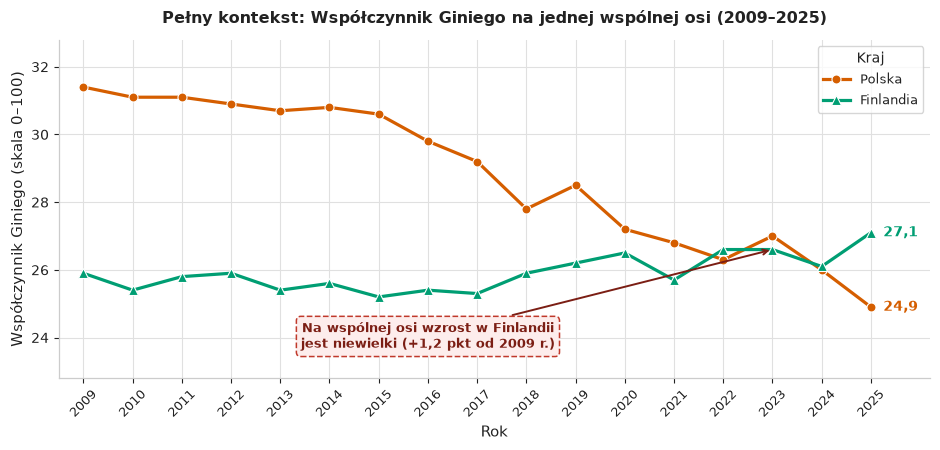

In [17]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))

ax.plot(
    df["year"], df["Polska"],
    color=COLOR_PL, marker="o", markersize=6.5, linewidth=2.3,
    markeredgecolor="white", markeredgewidth=0.8, label="Polska", zorder=3
)
ax.plot(
    df["year"], df["Finlandia"],
    color=COLOR_FI, marker="^", markersize=7, linewidth=2.3,
    markeredgecolor="white", markeredgewidth=0.8, label="Finlandia", zorder=3
)

ax.set_ylim(22.8, 32.8)
ax.set_xlim(2008.5, 2026.2)
ax.set_xticks(df["year"])
ax.set_xticklabels(df["year"], rotation=45, fontsize=9.5)
ax.set_ylabel("Współczynnik Giniego (skala 0–100)", fontsize=10.5)
ax.set_xlabel("Rok", fontsize=10.5)

ax.grid(True, color="#E0E0E0", linestyle="-", linewidth=0.8, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

pl_end = df["Polska"].iloc[-1]
fi_end = df["Finlandia"].iloc[-1]
ax.text(2025.25, pl_end, f"{pl_end:.1f}".replace(".", ","),
        va="center", ha="left", fontsize=10, fontweight="bold", color=COLOR_PL)
ax.text(2025.25, fi_end, f"{fi_end:.1f}".replace(".", ","),
        va="center", ha="left", fontsize=10, fontweight="bold", color=COLOR_FI)

ax.annotate(
    "Na wspólnej osi wzrost w Finlandii\njest niewielki (+1,2 pkt od 2009 r.)",
    xy=(2023, df.loc[df["year"] == 2023, "Finlandia"].values[0]),
    xytext=(2016.0, 23.7),
    arrowprops=dict(arrowstyle="->", color=COLOR_BAD_TITLE, lw=1.4),
    fontsize=9.2, fontweight="bold", color=COLOR_BAD_TITLE, ha="center",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#FDEDEC", edgecolor=COLOR_BAD, linestyle="--", lw=1.1)
)

ax.legend(title="Kraj", loc="upper right", frameon=True, facecolor="white", edgecolor="#CCCCCC", fontsize=9.5)
ax.set_title(
    "Pełny kontekst: Współczynnik Giniego na jednej wspólnej osi (2009–2025)",
    fontsize=11.5, fontweight="bold", color="#222222", pad=12
)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "gini_good.pdf", format="pdf", bbox_inches="tight")
plt.show()